# Spotify Music Analysis: Popularity and Audio Features

**Milestone 1 – CIE | Data Transformation, Null Value Handling, Insight Generation and Visualization**

This notebook demonstrates a complete beginner-friendly data analysis workflow using Pandas, NumPy, Matplotlib and Seaborn. The included CSV is a **synthetic practice dataset** created for this ready-to-run example; it is not a Spotify API export. If your instructor requires a real-world downloaded dataset, replace `spotify_tracks.csv` with the CSV downloaded from the source linked in the README and rerun the notebook.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

## 2. Read the CSV dataset

In [2]:
df = pd.read_csv('spotify_tracks.csv')
print('Dataset loaded successfully!')
print('Rows and columns:', df.shape)
df.head()

Dataset loaded successfully!
Rows and columns: (5000, 17)


,track_id,track_name,artists,album_name,track_genre,popularity,duration_ms,explicit,danceability,energy,loudness,acousticness,valence,tempo,speechiness,instrumentalness,liveness
0,id_000001,Track 1,Artist_264,Album_1405,rock,44.0,203075.0,False,0.425030,0.919966,-6.731222,0.462600,0.419765,0.627439,115.368431,0.119448,0.096753
1,id_000002,Track 2,Artist_160,Album_845,soul,19.0,163326.0,False,0.422420,0.479901,-6.951612,0.912205,0.150993,0.386002,83.350411,0.913434,0.902490
2,id_000003,Track 3,Artist_364,Album_878,blues,54.0,179157.0,False,0.404378,0.215889,-7.107474,0.012397,0.509735,0.538108,105.718686,0.507190,0.436989
3,id_000004,Track 4,Artist_097,Album_749,metal,45.0,281998.0,False,0.349730,1.000000,-13.577630,0.285221,0.692772,0.223682,153.787198,0.025040,0.262388
4,id_000005,Track 5,Artist_130,Album_594,metal,55.0,265390.0,True,0.408134,1.000000,-1.879697,0.654996,0.995555,0.515496,167.390608,0.015803,0.557583


## 3. Understand the dataset

In [3]:
print('Dataset dimensions:', df.shape)
print('\nColumn names:')
print(df.columns.tolist())
print('\nData types and non-null counts:')
df.info()

Dataset dimensions: (5000, 17)

Column names:
['track_id', 'track_name', 'artists', 'album_name', 'track_genre', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'loudness', 'acousticness', 'valence', 'tempo', 'speechiness', 'instrumentalness', 'liveness']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          5000 non-null   object 
 1   track_name        5000 non-null   object 
 2   artists           4992 non-null   object 
 3   album_name        4992 non-null   object 
 4   track_genre       5000 non-null   object 
 5   popularity        4940 non-null   float64
 6   duration_ms       4960 non-null   float64
 7   explicit          5000 non-null   bool   
 8   danceability      4925 non-null   float64
 9   energy            4940 non-null   float64
 10  loudness        

In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
track_id,5000,5000,id_000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_name,5000,5000,Track 1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artists,4992,400,Artist_029,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
album_name,4992,1443,Album_573,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_genre,5000,20,jazz,276,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,4940.0,NaN,NaN,NaN,38.269838,18.337245,0.0,26.0,38.0,51.0,100.0
duration_ms,4960.0,NaN,NaN,NaN,220362.054839,45077.484677,90000.0,190406.0,219975.5,251103.0,420000.0
explicit,5000,2,False,4071,NaN,NaN,NaN,NaN,NaN,NaN,NaN
danceability,4925.0,NaN,NaN,NaN,0.570656,0.215238,0.0,0.415,0.57982,0.738259,1.0
energy,4940.0,NaN,NaN,NaN,0.615987,0.248833,0.0,0.444717,0.64558,0.813365,1.0


## 4. Data transformation

In [5]:
# Remove duplicate records, if any
print('Duplicate rows before cleaning:', df.duplicated().sum())
df = df.drop_duplicates().copy()

# Convert data types to appropriate formats
numeric_columns = ['popularity', 'duration_ms', 'danceability', 'energy',
                   'loudness', 'acousticness', 'valence', 'tempo',
                   'speechiness', 'instrumentalness', 'liveness']
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df['explicit'] = df['explicit'].astype('boolean')

# Create a new column: duration in minutes
df['duration_min'] = df['duration_ms'] / 60000

# Create a popularity category
df['popularity_category'] = pd.cut(
    df['popularity'], bins=[-1, 39, 69, 100],
    labels=['Low', 'Medium', 'High']
)

# Drop an unnecessary identifier column for analysis (retain original df separately if needed)
analysis_df = df.drop(columns=['track_id'])
print('New columns added: duration_min, popularity_category')
analysis_df.head()

Duplicate rows before cleaning: 0
New columns added: duration_min, popularity_category


,track_name,artists,album_name,track_genre,popularity,duration_ms,explicit,danceability,energy,loudness,acousticness,valence,tempo,speechiness,instrumentalness,liveness,duration_min,popularity_category
0,Track 1,Artist_264,Album_1405,rock,44.0,203075.0,False,0.425030,0.919966,-6.731222,0.462600,0.419765,0.627439,115.368431,0.119448,0.096753,3.384583,Medium
1,Track 2,Artist_160,Album_845,soul,19.0,163326.0,False,0.422420,0.479901,-6.951612,0.912205,0.150993,0.386002,83.350411,0.913434,0.902490,2.722100,Low
2,Track 3,Artist_364,Album_878,blues,54.0,179157.0,False,0.404378,0.215889,-7.107474,0.012397,0.509735,0.538108,105.718686,0.507190,0.436989,2.985950,Medium
3,Track 4,Artist_097,Album_749,metal,45.0,281998.0,False,0.349730,1.000000,-13.577630,0.285221,0.692772,0.223682,153.787198,0.025040,0.262388,4.699967,Medium
4,Track 5,Artist_130,Album_594,metal,55.0,265390.0,True,0.408134,1.000000,-1.879697,0.654996,0.995555,0.515496,167.390608,0.015803,0.557583,4.423167,Medium


## 5. Identify and handle null values using mean imputation

In [6]:
# Count missing values in every column
missing_before = analysis_df.isnull().sum().sort_values(ascending=False)
print('Missing values before imputation:')
print(missing_before[missing_before > 0])

# Mean imputation is appropriate for numerical columns only.
# Categorical missing values are filled with the mode (most frequent value).
for col in numeric_columns:
    if analysis_df[col].isnull().sum() > 0:
        mean_value = analysis_df[col].mean()
        analysis_df[col] = analysis_df[col].fillna(mean_value)
        print(f'{col}: missing values filled with mean = {mean_value:.2f}')

for col in ['artists', 'album_name', 'track_name', 'track_genre']:
    if analysis_df[col].isnull().sum() > 0:
        analysis_df[col] = analysis_df[col].fillna(analysis_df[col].mode()[0])

# Recalculate derived columns after imputation
analysis_df['duration_min'] = analysis_df['duration_ms'] / 60000
analysis_df['popularity_category'] = pd.cut(analysis_df['popularity'], bins=[-1, 39, 69, 100], labels=['Low', 'Medium', 'High'])
print('\nTotal missing values after handling:', analysis_df.isnull().sum().sum())

Missing values before imputation:
danceability           75
popularity             60
energy                 60
popularity_category    60
tempo                  50
duration_min           40
duration_ms            40
artists                 8
album_name              8
dtype: int64
popularity: missing values filled with mean = 38.27
duration_ms: missing values filled with mean = 220362.05
danceability: missing values filled with mean = 0.57
energy: missing values filled with mean = 0.62
tempo: missing values filled with mean = 0.54

Total missing values after handling: 0


## 6. Generate insights

In [7]:
print('Total tracks:', len(analysis_df))
print('Number of genres:', analysis_df['track_genre'].nunique())
print('Number of unique artists:', analysis_df['artists'].nunique())
print('Average popularity:', round(analysis_df['popularity'].mean(), 2))
print('Average duration (minutes):', round(analysis_df['duration_min'].mean(), 2))
print('Average danceability:', round(analysis_df['danceability'].mean(), 3))
print('Average energy:', round(analysis_df['energy'].mean(), 3))

Total tracks: 5000
Number of genres: 20
Number of unique artists: 400
Average popularity: 38.27
Average duration (minutes): 3.67
Average danceability: 0.571
Average energy: 0.616


In [8]:
# Insight 1: Top 10 genres by average popularity
genre_popularity = (analysis_df.groupby('track_genre')['popularity']
                    .mean().sort_values(ascending=False))
print('Top 10 genres by average popularity:')
display(genre_popularity.head(10).round(2))

# Insight 2: Average audio features by genre
genre_features = analysis_df.groupby('track_genre')[
    ['danceability', 'energy', 'valence', 'acousticness']
].mean().round(2)
display(genre_features.head(10))

# Insight 3: Popularity category distribution
print(analysis_df['popularity_category'].value_counts())

Top 10 genres by average popularity:


track_genre
disco      45.00
k-pop      44.93
latin      44.67
hip-hop    44.34
house      43.93
pop        42.94
edm        42.87
punk       42.24
reggae     41.72
r&b        40.66
Name: popularity, dtype: float64

,danceability,energy,valence,acousticness
track_genre,,,,
ambient,0.22,0.20,0.49,0.51
blues,0.39,0.49,0.46,0.47
classical,0.27,0.19,0.48,0.49
country,0.55,0.53,0.52,0.48
disco,0.78,0.76,0.52,0.52
edm,0.71,0.86,0.50,0.47
folk,0.43,0.35,0.49,0.48
hip-hop,0.79,0.72,0.50,0.48
house,0.76,0.81,0.52,0.49


popularity_category
Low       2656
Medium    2122
High       222
Name: count, dtype: int64


## 7. Data visualization

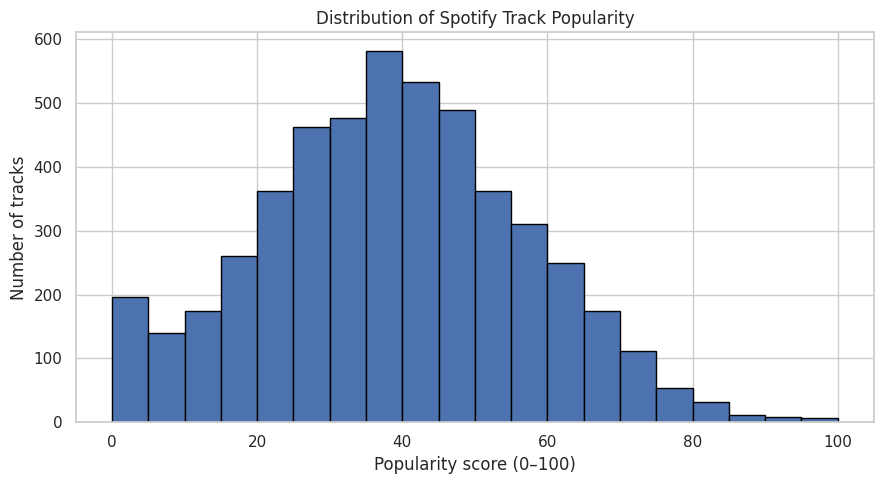

In [9]:
# Chart 1: Distribution of popularity scores
plt.figure(figsize=(9, 5))
plt.hist(analysis_df['popularity'], bins=20, edgecolor='black')
plt.title('Distribution of Spotify Track Popularity')
plt.xlabel('Popularity score (0–100)')
plt.ylabel('Number of tracks')
plt.tight_layout()
plt.show()

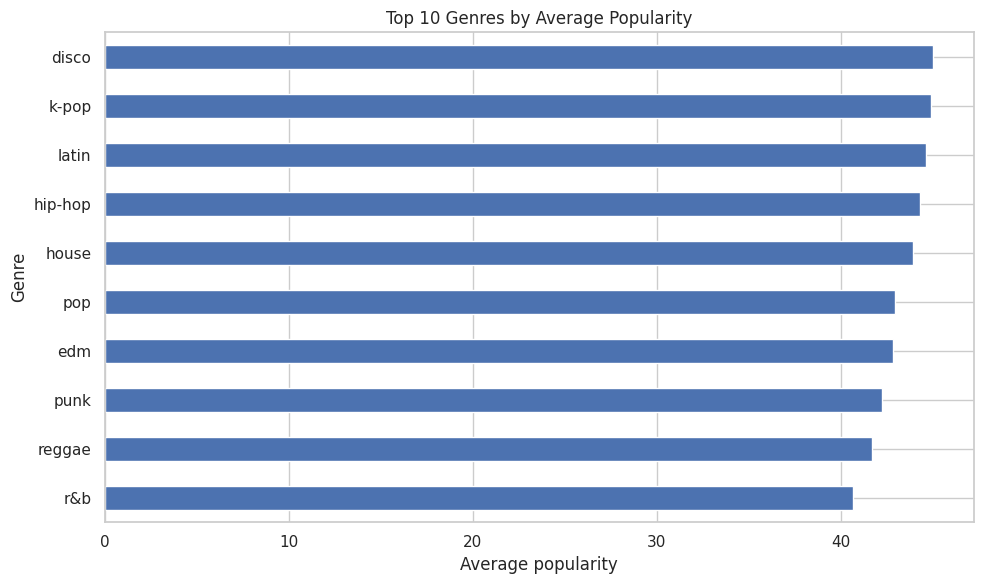

In [10]:
# Chart 2: Top 10 genres by average popularity
top10 = genre_popularity.head(10).sort_values()
plt.figure(figsize=(10, 6))
top10.plot(kind='barh')
plt.title('Top 10 Genres by Average Popularity')
plt.xlabel('Average popularity')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

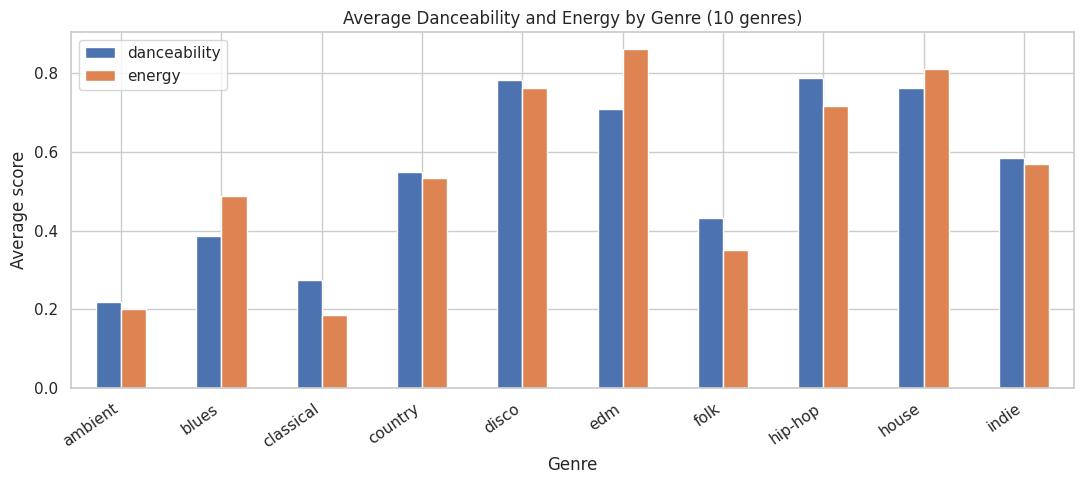

In [11]:
# Chart 3: Average danceability and energy by selected genres
selected_genres = analysis_df.groupby('track_genre')[['danceability', 'energy']].mean().head(10)
selected_genres.plot(kind='bar', figsize=(11, 5))
plt.title('Average Danceability and Energy by Genre (10 genres)')
plt.xlabel('Genre')
plt.ylabel('Average score')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

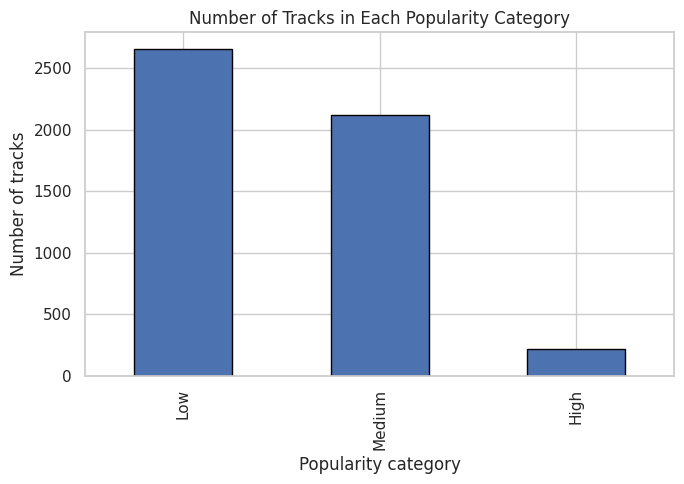

In [12]:
# Chart 4: Popularity category count
plt.figure(figsize=(7, 5))
analysis_df['popularity_category'].value_counts().reindex(['Low', 'Medium', 'High']).plot(kind='bar', edgecolor='black')
plt.title('Number of Tracks in Each Popularity Category')
plt.xlabel('Popularity category')
plt.ylabel('Number of tracks')
plt.tight_layout()
plt.show()

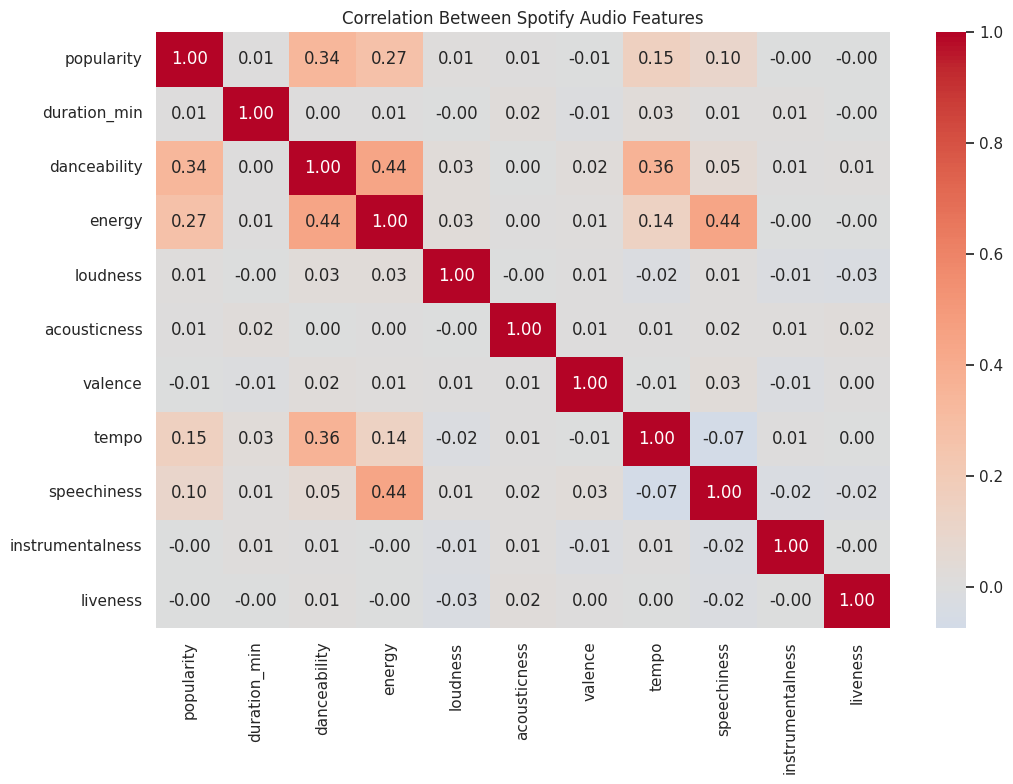

In [13]:
# Chart 5: Correlation heatmap of numerical audio features
corr_columns = ['popularity', 'duration_min', 'danceability', 'energy',
                'loudness', 'acousticness', 'valence', 'tempo',
                'speechiness', 'instrumentalness', 'liveness']
plt.figure(figsize=(11, 8))
sns.heatmap(analysis_df[corr_columns].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Between Spotify Audio Features')
plt.tight_layout()
plt.show()

## 8. Summary of findings

In [14]:
print('PROJECT INSIGHTS')
print('-' * 50)
print(f"1. The dataset contains {len(analysis_df):,} tracks across {analysis_df['track_genre'].nunique()} genres.")
print(f"2. The average popularity score is {analysis_df['popularity'].mean():.2f} out of 100.")
print(f"3. The average track duration is {analysis_df['duration_min'].mean():.2f} minutes.")
print(f"4. The most popular genre by average score is '{genre_popularity.index[0]}'.")
print(f"5. Average danceability is {analysis_df['danceability'].mean():.2f} and average energy is {analysis_df['energy'].mean():.2f}.")
print(f"6. Missing values remaining after cleaning: {analysis_df.isnull().sum().sum()}.")

PROJECT INSIGHTS
--------------------------------------------------
1. The dataset contains 5,000 tracks across 20 genres.
2. The average popularity score is 38.27 out of 100.
3. The average track duration is 3.67 minutes.
4. The most popular genre by average score is 'disco'.
5. Average danceability is 0.57 and average energy is 0.62.
6. Missing values remaining after cleaning: 0.


## 9. Conclusion

This project demonstrated how to load a CSV file, inspect its structure, transform columns, create new features, identify missing values, apply mean imputation to numerical columns, generate grouped insights and communicate patterns using visualizations. The charts help compare popularity across genres and examine relationships among audio features.

**Note:** Correlation does not prove causation. Popularity may be affected by many factors not included in this dataset.

## 10. Save the cleaned dataset

In [15]:
analysis_df.to_csv('spotify_tracks_cleaned.csv', index=False)
print('Cleaned dataset saved as spotify_tracks_cleaned.csv')

Cleaned dataset saved as spotify_tracks_cleaned.csv
